What Makes a Video Go Viral?

CSC 381-01 | Report 1 | 14 October 2026
Prof: Yunlong Wang

Stephen Handy | 0796861
Dataset: dataset/viral_videos.csv


1. Background
   We have all seen it – a viral video that we can talk about with friends, and sometimes family. Millions of views and shares connect us in a way that was inconceivable just a few decades past. Trends come and go, except mentioning a viral sensation still has an ability to bring us right back to the moment of laughter, shock, wonder, and respect that we first experienced during its exponential social onset. Many of us have dreamed of being a cultural reference like this, while others have so to their own detriment or demise. Either way, the real question is how does this occur? Which factors contribute to reproducible results to be a sensation? This aforementioned dataset explores this question in detail.


2. Problem Statement
   What Makes a Video Go Viral?

According to data gathered from 12,000 YouTube videos across various categories:
Which categories are most likely to achieve virality?
Do certain upload days and hours correlate with virality?


3. Data
Where it came from – Kaggle Datasets: https://www.kaggle.com/datasets/vedauv/what-makes-a-yt-video-go-viral-12000-vids/data
What one row represents – One row includes video ID, category, duration in seconds, title length, thumbnail, upload hour, upload day, tags count, description length, subscriber count, views, likes, comments, shares, and whether video is considered viral (top 20% of views).
How big it is – 12,000 rows and 15 columns
 <!-- Which columns I used –  -->


4. Analysis
    1. Compared viral rates by category. I grouped videos by category to calculate a mean of 'viral'. Viral is coded as a 0 (not viral) or 1 (viral), so this mean is a representation of a percentage of videos in each category classified as viral. Music is the highest result and vlogging is lowest.
    2. Compared viral rates by upload day and hour. I grouped videos by 'upload_day' and 'upload_hour' to calculate viral rate per group. Highest day was Wednesday and hour was 23:00. This suggests that audiences may wind down their evenings by watching content creators or searching specific categories of interest.
    3. Built a regression model to predict views. View counts are highly right-skewed, so I predicted 'log1p(views)' instead of raw views using category, characteristics, upload timing, and subscriber count as predictors. Original scale was used after calculation with 'expm1()'.
    4. These results show patterns and associations, not necessarily causation. A higher observed viral rate is not a guarantee of high likes and therefore viral outcome. Many factors contribute.


5. Visualization


In [1]:
%pip install seaborn

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("dataset/viral_videos.csv")
print(df.shape)
print(f"Viral rate: {df['viral'].mean()*100:.1f}%")
print(df.head())

days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
df["upload_day"] = pd.Categorical(
    df["upload_day"], categories = days, ordered = True
)

df["duration_group"] = pd.cut(
    df["duration_sec"],
    bins = [0, 300, 600, 900, 1200, np.inf],
    labels = ["0-5 min", "5-10 min", "10-15 min", "15-20 min", ">20 min"]
)



Note: you may need to restart the kernel to use updated packages.
(12000, 15)
Viral rate: 20.0%
     video_id category  duration_sec  title_length  thumbnail_face  \
0  vid_000001   Beauty           517            64               1   
1  vid_000002     Tech           495            47               1   
2  vid_000003   Beauty           311            76               0   
3  vid_000004  Fitness           590            69               0   
4  vid_000005     Tech           380            58               1   

   upload_hour upload_day  tags_count  description_length  subscriber_count  \
0           23        Wed          27                 429            907474   
1           23        Mon          10                 222           1004641   
2           17        Mon          13                 520            168170   
3            0        Mon          17                 309            285593   
4           19        Mon           0                 101           1073326   

    view

Highest category viral rate: Music (57.2%)
Lowest category viral rate: Vlog (7.2%)


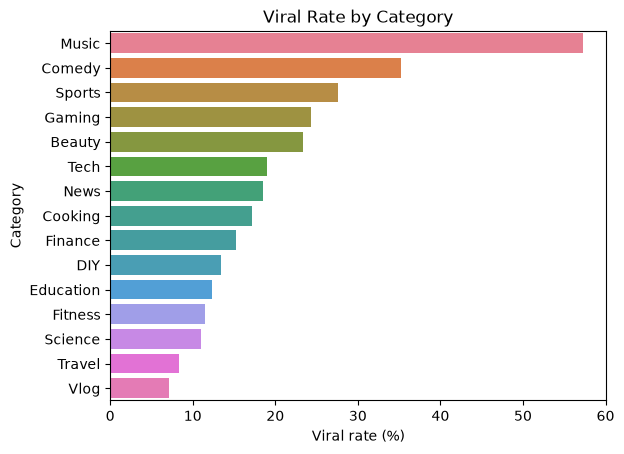

In [2]:
category_rate = (
    df.groupby("category", observed = True)["viral"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending = False)
)

category_rate["viral_rate_pct"] = category_rate["mean"] * 100

print(
    "Highest category viral rate:",
    category_rate.index[0],
    f"({category_rate.iloc[0]['viral_rate_pct']:.1f}%)"
)

print(
    "Lowest category viral rate:",
    category_rate["mean"].idxmin(),
    f"({category_rate['mean'].min() * 100:.1f}%)"
)

sns.barplot(
    data = category_rate.reset_index(),
    x = "viral_rate_pct",
    y = "category",
    hue = "category",
    legend = False
)
plt.xlabel("Viral rate (%)")
plt.ylabel("Category")
plt.title("Viral Rate by Category")
plt.show()


Highest day viral rate: Wed (20.8%)
Highest hour viral rate: 23 (24.0%)
Viral rate by upload day:


,viral_rate,count,viral_rate_pct
upload_day,,,
Wed,0.208262,1743,20.826162
Fri,0.206836,1697,20.683559
Mon,0.206168,1751,20.616790
Thu,0.203704,1728,20.370370
Tue,0.193608,1627,19.360787
Sun,0.193013,1746,19.301260
Sat,0.187939,1708,18.793911


Viral rate by upload hour:


,viral_rate,count,viral_rate_pct
upload_hour,,,
23,0.239583,480,23.958333
7,0.226263,495,22.626263
19,0.215686,510,21.568627
8,0.215606,487,21.560575
0,0.214859,498,21.485944
21,0.214149,523,21.414914
9,0.213592,515,21.359223
18,0.213333,525,21.333333
4,0.210117,514,21.011673


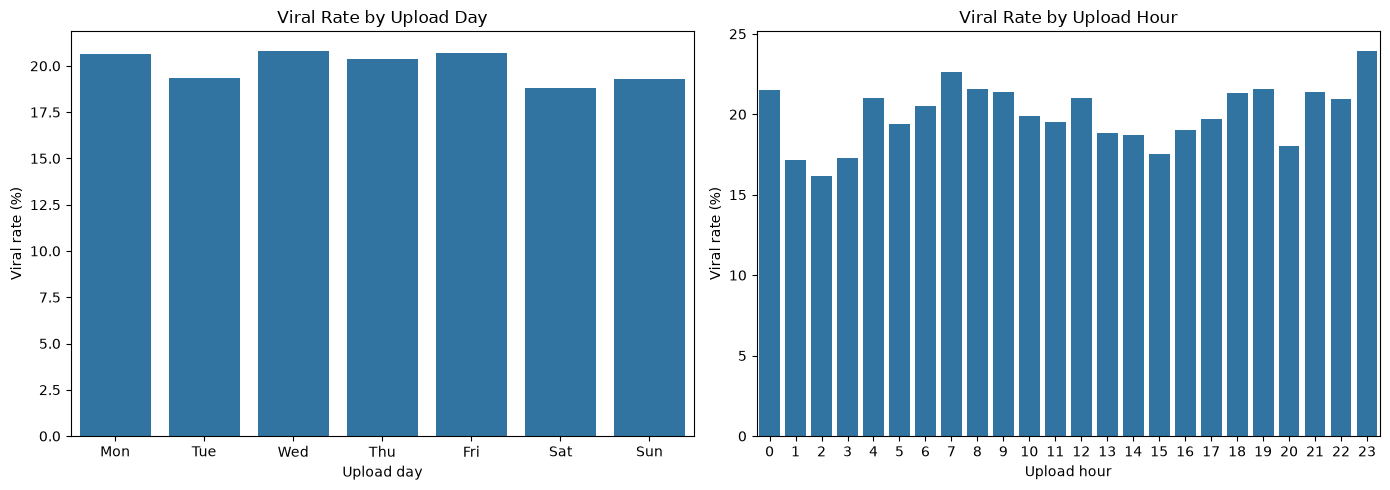

In [3]:
day_rate = (
    df.groupby("upload_day", observed=True)["viral"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "viral_rate"})
)

hour_rate = (
    df.groupby("upload_hour")["viral"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "viral_rate"})
)

day_rate["viral_rate_pct"] = day_rate["viral_rate"] * 100
hour_rate["viral_rate_pct"] = hour_rate["viral_rate"] * 100

print("Highest day viral rate:",
    day_rate["viral_rate"].idxmax(),
    f"({day_rate['viral_rate'].max() * 100:.1f}%)"
)

print("Highest hour viral rate:",
    hour_rate["viral_rate"].idxmax(),
    f"({hour_rate['viral_rate'].max() * 100:.1f}%)"
)

print("Viral rate by upload day:")
display(day_rate.sort_values("viral_rate", ascending=False))

print("Viral rate by upload hour:")
display(hour_rate.sort_values("viral_rate", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=day_rate.reset_index(),
    x="upload_day",
    y="viral_rate_pct",
    ax=axes[0]
)
axes[0].set_title("Viral Rate by Upload Day")
axes[0].set_xlabel("Upload day")
axes[0].set_ylabel("Viral rate (%)")

sns.barplot(
    data=hour_rate.reset_index(),
    x="upload_hour",
    y="viral_rate_pct",
    ax=axes[1]
)
axes[1].set_title("Viral Rate by Upload Hour")
axes[1].set_xlabel("Upload hour")
axes[1].set_ylabel("Viral rate (%)")

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

features = [
    "category",
    "duration_sec",
    "title_length",
    "thumbnail_face",
    "upload_hour",
    "upload_day",
    "tags_count",
    "description_length",
    "subscriber_count"
]

X = df[features]
y = np.log1p(df["views"])
# calculates log(1 + x) – reduces impact of extremely popular videos and right-skewed view counts distribution, making the regression model more robust to outliers.

categorical_features = ["category", "upload_day"]
numeric_features = [
    "duration_sec",
    "title_length",
    "thumbnail_face",
    "upload_hour",
    "tags_count",
    "description_length",
    "subscriber_count"
]

preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features), ("numeric", "passthrough", numeric_features)
])
# preproccesses data (transforms raw data to a format machine-learning can understand) and sends to linear regression model

model = Pipeline([
    ("preprocessor", preprocessor), ("regression", LinearRegression())
])

# split data – 80% training, 20% for testing, random_state=42 to make split reproducible
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# learns from training data and predicts log-transformed views for the test data
model.fit(X_train, y_train)
y_pred_log = model.predict(X_test)

# RMSE measures typical prediction error in the same units as the target variable (log-transformed views). R² indicates how well the model explains the variance in the target variable.
print(f"Log-scale RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_log)):.3f}")
print(f"Log-scale R²: {r2_score(y_test, y_pred_log):.3f}")

# converts back to estimated view counts using np.expm1() which calculates exp(x) - 1, reversing the earlier log(1 + x) transformation.
actual_views = np.expm1(y_test)
predicted_views = np.expm1(y_pred_log)

# MAE measures the average absolute difference between predicted and actual view counts, providing an interpretable metric of prediction accuracy in the original scale of views.
print(f"Views MAE: {mean_absolute_error(actual_views, predicted_views):,.0f}")

# This model predicts the logarithm of views, which reduces the influence of extremely popular videos. np.expm1() converts predictions back into estimated view counts.


Log-scale RMSE: 1.377
Log-scale R²: 0.262
Views MAE: 804,887


6. Conclusion
   Viral rates differ among various features – categories, upload days, and upload hours. Music and Comedy had the highest category viral rates, while vlogging and travel had the lowest. Grouped averages were used with category, day, and hour to identify highest observed viral rates. Content category and upload timing seem to suggest a high likelihood of virality. However, there is no strong correlation present with any such metric. This information can be used in tandem with personal analytics data and experimentation to increase likelihood of achieving success.


7. Limitations
   Several limitations are present in this dataset. Correlation is not causation – a higher viral rate does not guarantee a particular category will achieve success. Many other factors outside of this dataset may prove to cause viral sensations, such as current events, friend circles, and shock value. Patterns of viral content in this dataset assumes top 20% of content, and more content is added every day. Also, regression predicts views, except this may not be a guarantee of continued and customary behaviors by content consumers.
